# **Faster R-CNN Implementation**

### **1. Imports**

In [ ]:
import pandas as pd
import numpy as np
import os, math
import torch
from torchvision.models.detection import fasterrcnn_resnet50_fpn, FasterRCNN_ResNet50_FPN_Weights
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
import json
from collections import defaultdict
from pathlib import Path
from PIL import Image
import torch
from torchvision.transforms.functional import to_tensor
from torch.utils.data import DataLoader
from tqdm import tqdm
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import time
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
from torchvision.ops import box_iou
import config
import sys
sys.path.append(str(Path.cwd().parent))

In [8]:
print(f"Using device: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'}")

Using device: NVIDIA GeForce RTX 3060


### **2. Load pretrained model**

In [ ]:
def get_model(num_classes=5):
    # num_classes = 4 vehicle classes (car, bus, van, others) + 1 background class,
    # which torchvision detection models require
    # Load Faster R-CNN with a ResNet-50 FPN backbone, pretrained on COCO.
    # min_size/max_size = 640 match the 640x640 images from preprocessing, so no extra resizing
    model = fasterrcnn_resnet50_fpn(
        weights=FasterRCNN_ResNet50_FPN_Weights.COCO_V1,
        min_size=640, max_size=640
    )
    # Get the number of input features of the existing classification layer
    in_features = model.roi_heads.box_predictor.cls_score.in_features
    # Replace the COCO prediction head (91 classes) with a new head for our 5 classes
    model.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes)
    return model

### **3. Dataset Class**

In [ ]:
"""Loads prepared MIO-TCD localization images and their COCO-format annotations."""
class MioLocDataset(torch.utils.data.Dataset):
    def __init__(self, root, split, train=False):
        # Store the dataset folder and whether augmentation should be applied
        self.root, self.train = Path(root), train
        # Read the COCO annotation file for this split (train / val / test)
        data = json.loads((self.root / f'coco_{split}.json').read_text())
        self.images = data['images']
        # Group annotations by image id so each image's boxes can be found quickly
        self.anns = defaultdict(list)
        for a in data['annotations']:
            self.anns[a['image_id']].append(a)

    def __len__(self):
        # Number of images in this split
        return len(self.images)

    def __getitem__(self, i):
        info = self.images[i]
        # Load the image as RGB and convert to a float tensor scaled to [0, 1]
        img = to_tensor(Image.open(self.root / info['file_name']).convert('RGB'))
        anns = self.anns[info['id']]
        # COCO boxes are [x, y, width, height]; Faster R-CNN needs [x1, y1, x2, y2].
        # reshape(-1, 4) keeps the right shape for images with no objects
        boxes = torch.tensor([[a['bbox'][0], a['bbox'][1],
                               a['bbox'][0] + a['bbox'][2], a['bbox'][1] + a['bbox'][3]]
                              for a in anns], dtype=torch.float32).reshape(-1, 4)
        # Class ids (1-4); 0 is reserved for background
        labels = torch.tensor([a['category_id'] for a in anns], dtype=torch.int64)
        if self.train and torch.rand(1) < 0.5:  # horizontal flip augmentation for 50% of training images
            img = img.flip(-1) # mirror the image along its width
            # Mirror the boxes too: new x1 = width - old x2, new x2 = width - old x1
            boxes[:, [0, 2]] = img.shape[-1] - boxes[:, [2, 0]]
        return img, {'boxes': boxes, 'labels': labels}

def collate(batch):
    # Images have different numbers of boxes, so keep each batch as tuples of (images), (targets) instead of stacking them into one tensor
    return tuple(zip(*batch))

### **4. Training Loop**

In [ ]:
# Use the GPU if available, otherwise fall back to the CPU
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
root = config.LOCALIZATION_PROCESSED # prepared dataset folder, defined in config.py
CKPT = 'frcnn_latest.pt' # checkpoint file used to resume training
EPOCHS, BATCH, SAVE_EVERY = 3 , 4, 500   # save every 500 iterations

# Training set with flip augmentation switched on
train_ds = MioLocDataset(root, 'train', train=True)

model = get_model().to(device)
params = [p for p in model.parameters() if p.requires_grad] # Only optimise parameters that are trainable
optimizer = torch.optim.SGD(params, lr=0.005, momentum=0.9, weight_decay=0.0005) # SGD with momentum and weight decay (L2 regularisation)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=2, gamma=0.1) # Multiply the learning rate by 0.1 every 2 epochs
scaler = torch.amp.GradScaler('cuda') # Gradient scaler for mixed-precision (fp16) training -> reduce memory, speed up training

def save_ckpt(epoch, it):
    # Save everything needed to resume: weights, optimiser, scheduler and position in training
    tmp = CKPT + '.tmp'
    torch.save({'model': model.state_dict(), 'optimizer': optimizer.state_dict(),
                'scheduler': scheduler.state_dict(), 'epoch': epoch, 'iter': it}, tmp)
    os.replace(tmp, CKPT)   # atomic, so a crash mid-save can't corrupt the checkpoint

def make_batches(epoch):
    # same shuffle order for a given epoch, so resuming mid-epoch is exact
    g = torch.Generator().manual_seed(epoch) # seed from the epoch number
    idx = torch.randperm(len(train_ds), generator=g).tolist() # shuffled image indices
    return [idx[i:i + BATCH] for i in range(0, len(idx), BATCH)] # split into batches

# Resume from the last checkpoint if one exists
start_epoch, start_iter = 0, 0
if os.path.exists(CKPT):
    ck = torch.load(CKPT, map_location=device)
    model.load_state_dict(ck['model'])
    optimizer.load_state_dict(ck['optimizer'])
    scheduler.load_state_dict(ck['scheduler'])
    start_epoch, start_iter = ck['epoch'], ck['iter']
    print(f'Resumed from epoch {start_epoch}, iteration {start_iter}')

for epoch in range(start_epoch, EPOCHS):
    model.train() # training mode (returns losses when given targets)
    batches = make_batches(epoch)
    # Skip batches already completed if resuming mid-epoch
    skip = start_iter if epoch == start_epoch else 0
    loader = DataLoader(train_ds, batch_sampler=batches[skip:],
                        num_workers=0, collate_fn=collate)

    bar = tqdm(loader, total=len(batches), initial=skip, desc=f'epoch {epoch+1}/{EPOCHS}')
    for step, (imgs, targets) in enumerate(bar, start=skip):
        # Move the images and their boxes/labels to the GPU
        imgs = [i.to(device) for i in imgs]
        targets = [{k: v.to(device) for k, v in t.items()} for t in targets]
        with torch.autocast('cuda'): # run the forward pass in mixed precision
            # The model returns a dictionary of losses (classifier, box regression, objectness, RPN box regression)
            loss = sum(model(imgs, targets).values())
        optimizer.zero_grad() # clear gradients from the previous step
        scaler.scale(loss).backward() # backpropagate the scaled loss
        scaler.step(optimizer) # update the weights
        scaler.update() # adjust the scale factor for the next step
        bar.set_postfix(loss=f'{loss.item():.3f}') # show current loss on the progress bar

        # mid epoch checkpoint
        if (step + 1) % SAVE_EVERY == 0: save_ckpt(epoch, step + 1)

    scheduler.step() # update the learning rate at the end of each epoch
    save_ckpt(epoch + 1, 0) # end-of-epock checkpoint: resume starts at next epoch
    torch.save(model.state_dict(), f'frcnn_epoch{epoch}.pt') # keep weights from every epoch

epoch 3/3: 100%|██████████| 22000/22000 [2:26:06<00:00,  2.51it/s, loss=0.152]  


In [12]:
print(torch.cuda.is_available(), next(model.parameters()).device)

True cuda:0


### **5. Model Evaluation**

#### **5.1. Load the model and run inferences**

In [ ]:
SPLIT = 'test' # evaluate on the held-out test split
CLASSES = ['car', 'bus', 'van', 'others'] # class names in label order (ids 1-4)

model = get_model().to(device)
# Load the weights from the final training epoch (epochs are numbered from 0)
model.load_state_dict(torch.load('frcnn_epoch2.pt', map_location=device))  # evaluation mode
model.eval() # evaluate mode
# Keep very low-confidence detections so mAP can be computed over the full precision-recall curve
model.roi_heads.score_thresh = 0.001
model.roi_heads.detections_per_img = 100 # maximum detections per image

ds = MioLocDataset(root, SPLIT) # no augmentation for evaluation
loader = DataLoader(ds, batch_size=8, shuffle=False, num_workers=0, collate_fn=collate)

preds = []
with torch.no_grad():
    for imgs, _ in tqdm(loader, desc=f'inference ({SPLIT})'):
        with torch.autocast('cuda'):
            out = model([i.to(device) for i in imgs])
        preds += [{'boxes': o['boxes'].float().cpu(), 'scores': o['scores'].float().cpu(),
                   'labels': o['labels'].cpu()} for o in out]

inference (test): 100%|██████████| 1375/1375 [08:39<00:00,  2.65it/s]


#### **5.2. COCO mAP**

In [ ]:
# Convert predictions to the COCO results format: [x, y, width, height] boxes
results = []
for i, p in enumerate(preds):
    image_id = ds.images[i]['id'] # match the prediction to its image id
    for b, s, l in zip(p['boxes'].tolist(), p['scores'].tolist(), p['labels'].tolist()):
        results.append(dict(image_id=image_id, category_id=int(l),
                            bbox=[b[0], b[1], b[2]-b[0], b[3]-b[1]], score=s))

gt = COCO(f'{root}/coco_{SPLIT}.json') # ground-truth annotations
dt = gt.loadRes(results) # our detections
E = COCOeval(gt, dt, 'bbox') # evaluate bounding-box detections
E.evaluate(); E.accumulate(); E.summarize() # run the COCO evaluation and print the summary

# stats[0] = mAP averaged over IoU 0.5 to 0.95, stats[1] = mAP at IoU 0.5
map_5095, map_50 = E.stats[0], E.stats[1]
print(f'\nmAP@0.5      = {map_50:.4f}')
print(f'mAP@0.5:0.95 = {map_5095:.4f}')

prec = E.eval['precision'] # IoU thresholds, recall thresholds, classes, area, maxDets
def class_ap(k, iou_idx=None):
    # Average precision for class k (area = all, maxDets = 100).
    # iou_idx=0 selects IoU 0.5; None averages over all IoU thresholds
    p = prec[:, :, k, 0, 2] if iou_idx is None else prec[iou_idx, :, k, 0, 2]
    p = p[p > -1] # drop recall levels with no valid precision (-1)
    return float(p.mean()) if p.size else float('nan')

ap50   = [class_ap(k, 0) for k in range(4)] # per-class AP at IoU 0.5
ap5095 = [class_ap(k) for k in range(4)] # per-class AP at IoU 0.5:0.95
for name, a, b in zip(CLASSES, ap50, ap5095):
    print(f'{name:8s} AP@0.5 = {a:.4f}   AP@0.5:0.95 = {b:.4f}')

loading annotations into memory...
Done (t=0.10s)
creating index...
index created!
Loading and preparing results...
DONE (t=1.03s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=16.76s).
Accumulating evaluation results...
DONE (t=4.29s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.660
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.858
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.752
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.306
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.609
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.819
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.567
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.773
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDet

#### **5.3. Precision, Recall and F1 Confusion Matrix**

In [17]:
CONF, IOU_T = 0.5, 0.5
cm = np.zeros((5, 5), dtype=int)   # rows = true (4 classes + background), cols = predicted

for i, p in enumerate(preds):
    info = ds.images[i]
    g = ds.anns[info['id']]
    gt_boxes = torch.tensor([[a['bbox'][0], a['bbox'][1], a['bbox'][0]+a['bbox'][2],
                              a['bbox'][1]+a['bbox'][3]] for a in g]).reshape(-1, 4).float()
    gt_lab = [a['category_id'] - 1 for a in g]

    keep = p['scores'] >= CONF
    pb, pl = p['boxes'][keep], (p['labels'][keep] - 1).tolist()
    order = p['scores'][keep].argsort(descending=True).tolist()
    used = set()
    iou = box_iou(pb, gt_boxes) if len(pb) and len(gt_boxes) else None

    for j in order:
        best, best_iou = -1, IOU_T
        if iou is not None:
            for k in range(len(gt_lab)):
                if k not in used and iou[j, k] >= best_iou:
                    best, best_iou = k, iou[j, k]
        if best >= 0:
            used.add(best); cm[gt_lab[best], pl[j]] += 1
        else:
            cm[4, pl[j]] += 1 # false positive
    for k in range(len(gt_lab)):
        if k not in used: cm[gt_lab[k], 4] += 1 # missed object

print(f'\nAt confidence >= {CONF}, IoU >= {IOU_T}')
for k, name in enumerate(CLASSES):
    tp = cm[k, k]; fp = cm[:, k].sum() - tp; fn = cm[k, :].sum() - tp
    P = tp / (tp + fp) if tp + fp else 0
    R = tp / (tp + fn) if tp + fn else 0
    F1 = 2*P*R / (P+R) if P + R else 0
    print(f'{name:8s} precision={P:.3f}  recall={R:.3f}  F1={F1:.3f}')


At confidence >= 0.5, IoU >= 0.5
car      precision=0.799  recall=0.922  F1=0.856
bus      precision=0.886  recall=0.907  F1=0.896
van      precision=0.659  recall=0.558  F1=0.604
others   precision=0.726  recall=0.749  F1=0.737


#### **5.4. Inference Speed**

In [18]:
model.roi_heads.score_thresh = 0.05
img = ds[0][0].to(device)
with torch.no_grad(), torch.autocast('cuda'):
    for _ in range(10): model([img]) # warm-up
    torch.cuda.synchronize(); t = time.time()
    for _ in range(100): model([img])
    torch.cuda.synchronize()
fps = 100 / (time.time() - t)
print(f'Inference speed: {fps:.1f} FPS (batch 1, 640x640, fp16, RTX 3060)')

Inference speed: 25.1 FPS (batch 1, 640x640, fp16, RTX 3060)


#### **5.5. Visualisations**

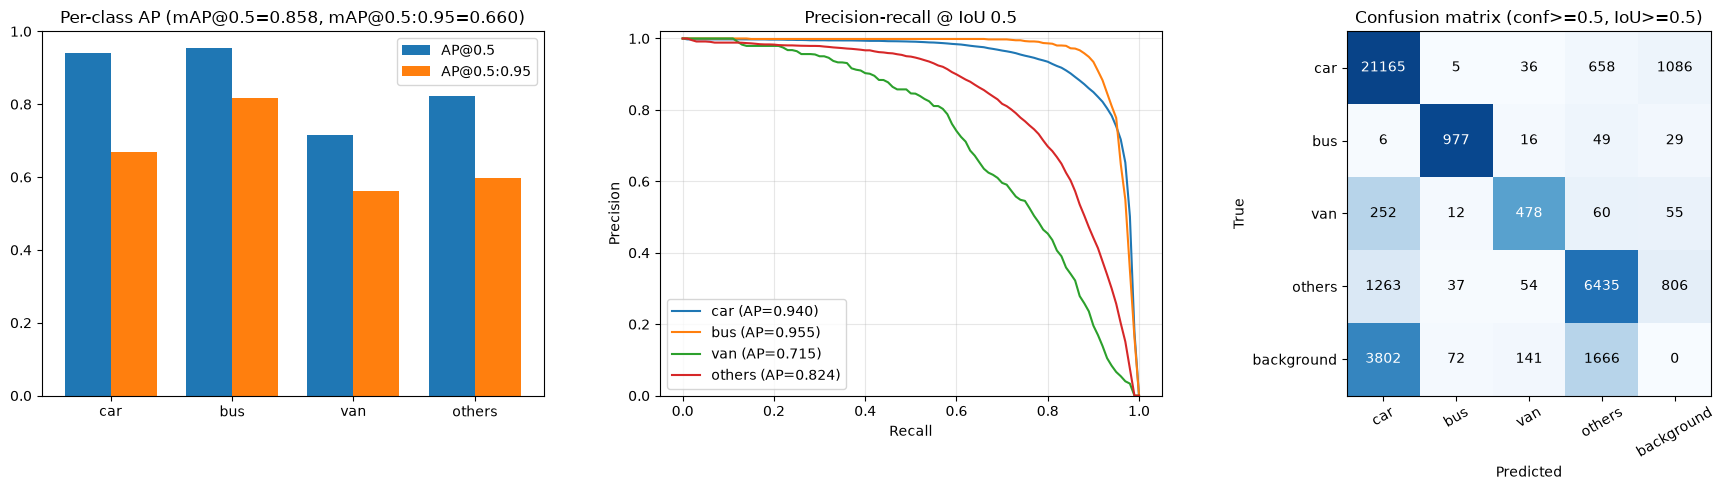

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# per-class AP
x = np.arange(4); w = 0.38
axes[0].bar(x - w/2, ap50, w, label='AP@0.5')
axes[0].bar(x + w/2, ap5095, w, label='AP@0.5:0.95')
axes[0].set_xticks(x); axes[0].set_xticklabels(CLASSES); axes[0].set_ylim(0, 1)
axes[0].set_title(f'Per-class AP (mAP@0.5={map_50:.3f}, mAP@0.5:0.95={map_5095:.3f})'); axes[0].legend()

# precision-recall curves at IoU 0.5
rec = E.params.recThrs
for k, name in enumerate(CLASSES):
    p = prec[0, :, k, 0, 2]
    axes[1].plot(rec, p, label=f'{name} (AP={ap50[k]:.3f})')
axes[1].set_xlabel('Recall'); axes[1].set_ylabel('Precision'); axes[1].set_ylim(0, 1.02)
axes[1].set_title('Precision-recall @ IoU 0.5'); axes[1].legend(); axes[1].grid(alpha=.3)

# confusion matrix (row-normalised colours, raw counts as text)
labels5 = CLASSES + ['background']
norm = cm / cm.sum(axis=1, keepdims=True).clip(min=1)
axes[2].imshow(norm, cmap='Blues', vmin=0, vmax=1)
for r in range(5):
    for c in range(5):
        axes[2].text(c, r, cm[r, c], ha='center', va='center',
                     color='white' if norm[r, c] > .5 else 'black')
axes[2].set_xticks(range(5)); axes[2].set_xticklabels(labels5, rotation=30)
axes[2].set_yticks(range(5)); axes[2].set_yticklabels(labels5)
axes[2].set_xlabel('Predicted'); axes[2].set_ylabel('True')
axes[2].set_title(f'Confusion matrix (conf>={CONF}, IoU>={IOU_T})')

plt.tight_layout(); plt.savefig('./rcnn-eval-images/frcnn_eval_summary.png', dpi=150); plt.show()

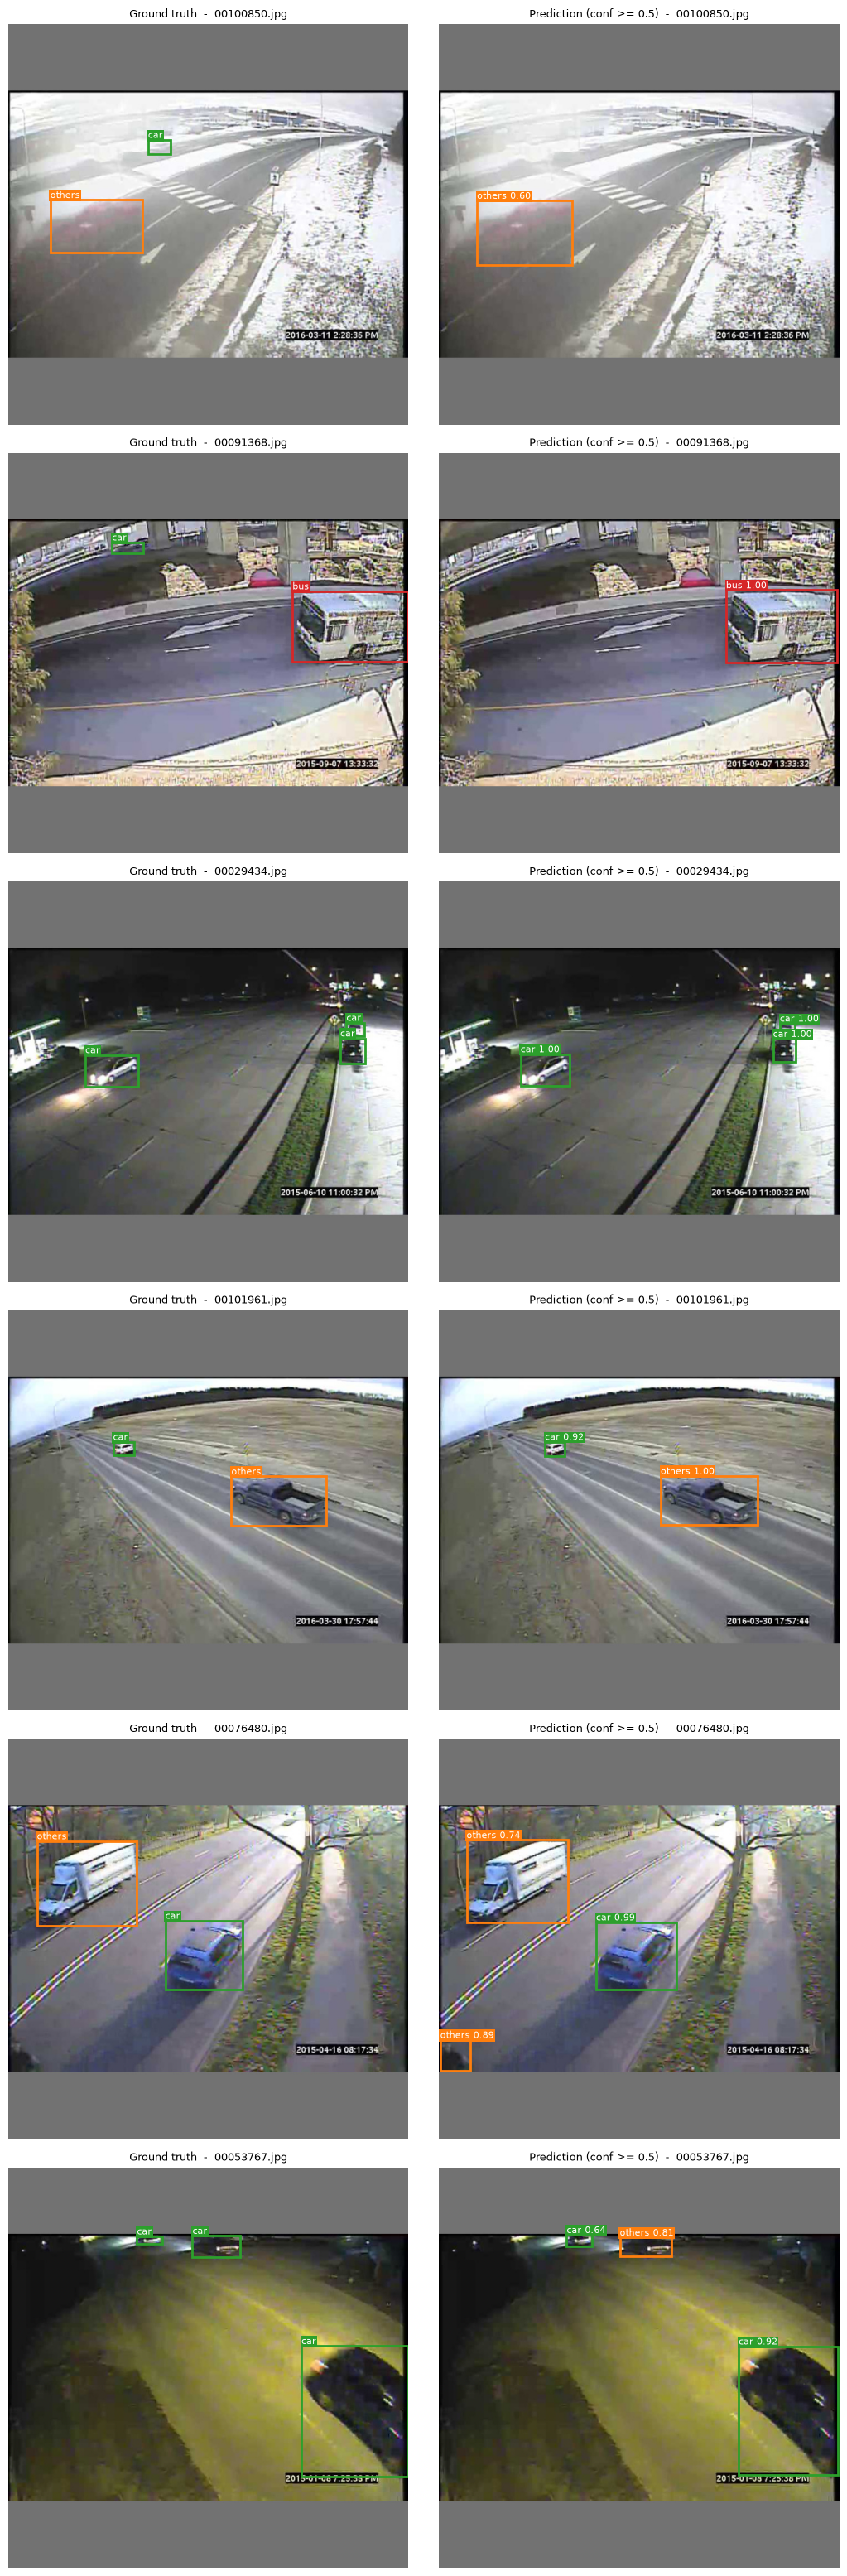

In [23]:
# Ground truth vs prediction on random test images
COLORS = {1: 'tab:green', 2: 'tab:red', 3: 'tab:blue', 4: 'tab:orange'}
rng = np.random.default_rng(0)
picks = rng.choice(len(ds), 6, replace=False)

fig, axes = plt.subplots(len(picks), 2, figsize=(11, 5.2 * len(picks)))
for row, i in enumerate(picks):
    info = ds.images[i]
    im = Image.open(Path(root) / info['file_name']).convert('RGB')
    for col, title in enumerate(['Ground truth', f'Prediction (conf >= {CONF})']):
        ax = axes[row, col]; ax.imshow(im); ax.axis('off'); ax.set_title(f'{title}  -  {info["file_name"].split("/")[-1]}', fontsize=9)
    for a in ds.anns[info['id']]:
        x, y, bw, bh = a['bbox']
        axes[row, 0].add_patch(patches.Rectangle((x, y), bw, bh, fill=False, lw=2, ec=COLORS[a['category_id']]))
        axes[row, 0].text(x, y-3, CLASSES[a['category_id']-1], color='white', fontsize=8,
                          bbox=dict(fc=COLORS[a['category_id']], pad=1, ec='none'))
    p = preds[i]
    for b, s, l in zip(p['boxes'].tolist(), p['scores'].tolist(), p['labels'].tolist()):
        if s < CONF: continue
        axes[row, 1].add_patch(patches.Rectangle((b[0], b[1]), b[2]-b[0], b[3]-b[1], fill=False, lw=2, ec=COLORS[l]))
        axes[row, 1].text(b[0], b[1]-3, f'{CLASSES[l-1]} {s:.2f}', color='white', fontsize=8,
                          bbox=dict(fc=COLORS[l], pad=1, ec='none'))
plt.tight_layout(); plt.savefig('rcnn-eval-images/frcnn_predictions.png', dpi=120); plt.show()